# 03 ベースラインの評価（段C）：否定クエリを増やして nDCG・トラップ率で測る

02 で1クエリ（7751）でやったことを関数にまとめて、何クエリでも回せるようにする。
- 02 の結果まとめ：TF-IDF 4/5・BM25 5/5（上位10件の radio 付き）。ラベルは見た目で付いている
- 計画：`00 ここから読む` の「C の進め方」2・3

流れ：データ → 前処理 → モデル（TF-IDF・BM25）→ 評価（nDCG・トラップ率）
**クエリ選び（4）は一緒に決める。** それまでは 7751 だけで動作確認。

In [78]:
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import ndcg_score
from rank_bm25 import BM25Okapi

## 1. データ（02 と同じ merge）

In [79]:
df_ex = pd.read_parquet('../data/examples_us.parquet')
df_pr = pd.read_parquet('../data/products_us.parquet')
df_merged = pd.merge(df_ex, df_pr, on=['product_id', 'product_locale'], how='left')
df_merged.shape

(601354, 14)

## 2. 前処理：1クエリ分の候補を作る（02 のセル 2〜3 を関数にする）

**なぜ必要？**
02 では 7751 のために、絞り込み → 文書の列 → radio の列、を1行ずつ書いた。クエリを20件にすると、それを20回書くことになる。
→ 「クエリ番号と除外したい語を渡すと、そのクエリの候補表が返ってくる」関数にしておけば、何件でも1行で呼べる。

**入力**
- `query_id`：例 7751
- `trap_word`：除外したい語。例 `'radio'`

**やること（02 と同じ）**
1. `df_merged` からそのクエリの行だけ取る（`.copy()` を忘れずに）
2. 文書＝タイトル＋説明（欠損は空文字）→ HTML タグを消す → `doc` 列
3. タイトルに `trap_word` があるか（大文字小文字は無視）→ `has_trap` 列（True/False）

**完成形（返すもの）**
- 7751・'radio' で呼ぶと：**17行**の表。列は元の列＋ `doc`・`has_trap`
- `has_trap` が True なのは **5行**（02 で数えた数と同じになれば正解）

In [80]:
def get_candidates(query_id, trap_word):
    # 1. このクエリの候補だけにする
    df_q = df_merged[df_merged['query_id'] == query_id].copy()

    # 2. doc 列を作る（タイトル＋説明 → HTML タグを消す）
    df_q['doc'] = df_q['product_title'].fillna('') + ' ' + df_q['product_description'].fillna('')
    df_q['doc'] = df_q['doc'].str.replace(r'<[^>]+>', ' ', regex=True)

    # 3. has_trap 列を作る（タイトルに trap_word があるか）
    df_q['has_trap'] = df_q['product_title'].str.contains(trap_word, case=False, regex=False).astype(int)

    return df_q  # 候補の表（DataFrame）


# 確認：17 と 5 が出れば OK
df_q = get_candidates(7751, 'radio')
print(len(df_q), df_q['has_trap'].sum())

17 5


## 3. モデル：点数を付けて並べる（02 の TF-IDF・BM25 を関数にする）

**なぜ必要？**
02 では TF-IDF と BM25 で書き方がバラバラで、`result`・`result_with`・`top10` と変数が増えて混乱した。
→ 2つとも「**候補の表とクエリを渡すと、`score` 列が付いて点の高い順に並んだ表が返る**」同じ形にそろえる。形がそろうと、評価（4）も同じ関数で測れる。

**3つ作る**
- `tokenize(text)`：文を単語のリストにする（BM25 用）。02 の `re.findall(r'\b\w\w+\b', ...)` と同じ。小文字にするのを忘れずに
- `rank_tfidf(df_q, query)`：02 のセル「4. モデル」「5. 点数を付けて並べる」と同じ流れ（fit_transform → transform → cosine_similarity）
- `rank_bm25(df_q, query)`：02 の一番下の BM25 と同じ流れ（tokenize → BM25Okapi → get_scores）

**完成形（返すもの）**
- 元の表に `score` 列が足されて、`score` の大きい順に並んだ表（17行）
- ヒント：`df_q.assign(score=...)` と `sort_values(..., ascending=False)`

In [81]:
def tokenize(text):
    # 小文字にして、2文字以上の単語を取り出す
    text = text.lower()
    words = re.findall(r'\b\w\w+\b', text)
    return words  # 単語のリスト


def rank_tfidf(df_q, query):
    # 1. TfidfVectorizer で doc 列をベクトルにする（fit_transform）
    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(df_q['doc'])
    

    # 2. クエリを同じ辞書でベクトルにする（transform）
    query_vector = vectorizer.transform([query])

    # 3. コサインで点数を出す
    scores = cosine_similarity(query_vector, tfidf_matrix).flatten()
    # 4. score 列を足して、点の高い順に並べる
    df_q['score'] = scores
    df_q_sorted = df_q.sort_values(by='score', ascending=False)
    return df_q_sorted  # 並べた表


def rank_bm25(df_q, query):
    # 1. doc 列を全部 tokenize して BM25Okapi に渡す
    tokenized_docs = df_q['doc'].apply(tokenize).tolist()
    bm25 = BM25Okapi(tokenized_docs)
    

    # 2. クエリも tokenize して点数を出す（get_scores）
    tokenized_query = tokenize(query)
    scores = bm25.get_scores(tokenized_query)

    # 3. score 列を足して、点の高い順に並べる
    df_q['score'] = scores
    df_q_sorted = df_q.sort_values(by='score', ascending=False)
    return df_q_sorted  # 並べた表


# 確認：上位10件の has_trap の数が TF-IDF 4・BM25 5 なら 02 と同じ
print(rank_tfidf(df_q, 'alarm clock without radio').head(10)['has_trap'].sum())
print(rank_bm25(df_q, 'alarm clock without radio').head(10)['has_trap'].sum())

4
5


## 4. 評価の物差し

**なぜ2つ必要？**
- **nDCG@k**（ラベルで測る。0〜1、1 に近いほど良い）：「良い物（E）が上に並んでいるか」
  - ⚠️ radio 付きでも E が付いていれば良い物扱い → 否定を守れたかは分からない（02 の結果まとめ参照）
- **トラップ率@k**（文で測る。0〜1、**0 に近いほど良い**）：上位 k 件のうち、除外したい語がタイトルにある件数 ÷ k
  - nDCG が見抜けない所を補う。出どころは 00 の「C の進め方」3（2026-10-24）

**ラベルを点にする（nDCG 用）**
E=1.0・S=0.1・C=0.01・I=0（ESCI 論文の重み）→ `GAIN` の辞書にしておく

**完成形**
- `ndcg_at_k(ranked, k=10)` → 1つの数字（0〜1）
  - ヒント：`sklearn.metrics.ndcg_score`。入力は「正解の点のリスト」と「モデルの点のリスト」を**それぞれ [ ] で1段包む**（1クエリ分＝1行の形）
  - 正解の点：`esci_label` を `GAIN` で変換（`.map()`）
- `trap_rate_at_k(ranked, k=10)` → 1つの数字（0〜1）
  - 7751 なら TF-IDF **0.4**・BM25 **0.5** になれば正解（02 の 4 件・5 件 ÷ 10）

In [82]:
GAIN = {'E': 1.0, 'S': 0.1, 'C': 0.01, 'I': 0.0}


def ndcg_at_k(ranked, k=10):
    # 1. 正解の点：esci_label を GAIN で数字にする
    ranked['esci_gain'] = ranked['esci_label'].map(GAIN)

    # 2. モデルの点：score 列
    
    ranked['score'] = ranked['score'].fillna(0)

    # 3. ndcg_score に渡す（両方 [ ] で包む、k も渡す）
    ndcg = ndcg_score([ranked['esci_gain'].values], [ranked['score'].values], k=k)
    return  ndcg  # 0〜1 の数字


def trap_rate_at_k(ranked, k=10):
    # 上位 k 件の has_trap の数 ÷ 枠の数（候補が k 件未満なら候補の数）
    slots = min(k, len(ranked))
    trap_rate = ranked.head(k)['has_trap'].sum() / slots
    return  trap_rate  # 0〜1 の数字

## 5. 動作確認：7751 だけ
- まず予想を1行：nDCG はどちらが高い？ トラップ率は？
- 2〜4 の関数を使って、TF-IDF と BM25 の nDCG@10・トラップ率@10 を print する

In [83]:
# 予想：nDCG は BM25 の方が低い（前回も BM25 の方が精度が悪かった）。トラップ率は小さめに収まる
#       （説明には radio があったがタイトルには少ない。"like a radio" も除外できたから）

df_q = get_candidates(7751, 'radio')
for name, rank in [('TF-IDF', rank_tfidf), ('BM25', rank_bm25)]:
    ranked = rank(df_q, df_q['query'].iloc[0])
    print(f'=== {name} ===')
    print(f'NDCG@10: {ndcg_at_k(ranked, k=10)}')
    print(f'Trap Rate@10: {trap_rate_at_k(ranked, k=10)}')

=== TF-IDF ===
NDCG@10: 0.8326954074719034
Trap Rate@10: 0.4
=== BM25 ===
NDCG@10: 0.7758280281938498
Trap Rate@10: 0.5


結果的に予想通りになったって感じだよね。 BM 25の方が悪かった。

### 予想と結果（2026-10-29・Claude が整理）
| | 予想 | 結果 | 合った？ |
|---|---|---|---|
| nDCG@10 | BM25 の方が低い | TF-IDF **0.833**・BM25 **0.776** | ✅ |
| トラップ率@10 | 小さめに収まる | TF-IDF **0.4**・BM25 **0.5** | ❌ |

**トラップ率がずれた理由**
- トラップ率は**タイトルに radio がある商品**（`has_trap`）だけを数える。候補17件のうち5件
- 予想の根拠だった「説明の radio」「"like a radio"（DreamCaster）」は、タイトルを見ないので**もともと数に入っていない**
- 実際は、タイトルに radio がある5件のうち、TF-IDF は4件・BM25 は**5件全部**を上位10件に入れた

**BM25 のトラップ率 0.5 の中身**
- 上位10件のうち5件が、タイトルに radio がある商品（1・2・4・5・7位）
- つまり BM25 は、radio 付きを1つ残らず上の方に集めた

**一番大事な結果**
- 「BM25 の方が悪い」は nDCG でもトラップ率でも合っている
- ただ TF-IDF でも上位10件の4割が罠 → **どちらも否定（without radio）を守れていない**
- 1クエリだけなので、まだ傾向。6・7番でクエリを増やして確かめる


## 6. クエリを選ぶ（一緒に決める）
- 否定の形：without / no / not / non- / free など
- 除外したい語（trap_word）を1つずつ決める
- 決まったら下の表に足す

In [84]:
#仕分け
#否定の取り出しコマンド
negative_q_key = r'\b(without|not|no|non|free|except|exclu\w*)\b'

target_negation = ['query_id', 'query']

#drop duplicates
df_queries = df_merged[target_negation].drop_duplicates()

#pick negative random 20 queries
df_negative = df_queries[df_queries['query'].str.contains(negative_q_key, case=False)].sample(n=20, random_state=42)
df_negative

queries = [
    # (query_id, trap_word)  ← 仕分け：Obsidian「09b 否定クエリの仕分けと採点の限界（2026-10-29）」の ✅
    (7751, 'radio'),         # alarm clock without radio
    (1571, 'wifi'),          # 10gb router without wifi
    (104756, 'almond'),      # trail mix without almonds
    (894, 'adapter'),        # 1 tb micro sd card without adapter
    (71582, 'vitamin k'),    # multivitamin without vitamin k
    (1466, 'added sugar'),   # 100% montmorency tart cherry juice without added sugar
    (41596, 'fluoride'),     # fluride free filter（クエリは打ち間違い）
]

/var/folders/k_/xfq6fm9x7419_ttdxwb035v80000gn/T/ipykernel_66254/3415445000.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_negative = df_queries[df_queries['query'].str.contains(negative_q_key, case=False)].sample(n=20, random_state=42)


## 6b. クエリの選び方を決め直す（2026-10-30）

### 簡単・難しい・否定ではない、の定義
- **✅ 簡単**：次の3つを全部満たす
  1. クエリが本当に「除外」を言っている（without / no / not / free など）
  2. 外したい物が **1〜2語の trap_word** で言える（radio・wifi・microphone）
  3. **商品タイトルに trap_word があれば、ほぼ確実にその物が入っている**（＝タイトルの文字一致で採点して大丈夫）
- **🤔 難しい**（今は使わない）：3 が崩れるもの
  - 欲しい商品がタイトルに「〜なし」と書く：backless・iron free・no wifi needed・"Not Fit … Plus"・"Will Not Fit Kindle Paperwhite"
  - trap_word が短くて別の語の一部に当たる（lid → solid、rc → force）
  - 外したい物が曖昧・文が崩れている
- **❌ 否定ではない**：本・ゲーム・商品の題名（"you cannot start without me"）、機能が**ある**ことを言う（hands free）
- 候補の中に罠が0件（測れない）／ほぼ全部が罠（並べ方で差が出ない）のクエリも外す

### こういう運用にした
- **まず簡単なものだけで測る**。はっきりした否定ですら守れないなら、それは採点のせいではなく**検索のせい**と言える。難しいものは、採点を意味で判定できるようにする v2 で扱う
- 選んでいる途中で、ESCI に **train と test が混ざっている**ことに気づいた（昨日の7件は test 3件・train 4件）。v2 で train を使って学習するときに「学習で見たクエリで評価した」にならないよう、**評価用のクエリは test だけから選ぶ**
- 選び方：test の否定クエリ（760件）を **seed 42 で1回だけシャッフル** → **上から順に**見て、✅ が20件たまったら止める（同じクエリが2回出ない・誰がやっても同じ順番）
- 結果：**上から326件を見て、✅ 20件**。仕分けは Claude（タイトルを見て 3 を確認）、本人が確認
- 昨日の7件（7751 など）は入れ替え。7751 は 335番目なので今回の20件には入らない（基準の例としては引き続き使う）
- この節のコードは Claude が書いた（EDA で決めた方針を運用に回す部分・2026-10-30 本人了承）


In [85]:
# test の否定クエリを seed 42 で1回シャッフル（上から順に仕分けた）
negative_q_key = r'\b(?:without|not|no|non|free|except|exclu\w*)\b'
df_test = df_merged[df_merged['split'] == 'test'][['query_id', 'query']].drop_duplicates()
df_neg_test = df_test[df_test['query'].str.contains(negative_q_key, case=False)].sample(frac=1, random_state=42)
print(len(df_neg_test))  # 760
df_neg_test.head(30)


760


,query_id,query
197038,34310,dog bowl stand without bowls
122968,18553,boppy nursing pillow without cover
10785,594,0pi nail polish i'm not really a waitress
304247,55882,jesus without cross
12046,642,1 12 off-road vehicle not rc
310599,57046,katie lee biegel cookbook it's not complicated
60584,5918,a world without soil
415799,78321,pc headphones without microphone
517163,99548,surviving not thriving
394677,74083,no more independent reading without support


In [86]:
# ✅ 簡単な20件（左の番号＝シャッフル後の順番）。上の7件の queries を置き換える
queries = [
    (71987, 'kn95'),         # 30  n95 not kn95 masks
    (23909, 'chicken'),      # 37  cat treats without chicken
    (115782, 'hood'),        # 71  zippered sweatshirt without hood mens
    (1435, 'controller'),    # 79  100 watt folding solar panel without charge controller
    (59940, 'chromebook'),   # 90  laptop not chromebook
    (40132, 'pop it'),       # 93  fidget pack without pop it
    (1509, 'controller'),    # 107 100w solar panel without controller
    (1400, 'microphone'),    # 124 100 headset without micrphone（クエリは打ち間違い）
    (78323, 'microphone'),   # 148 pc headset without microphone
    (99719, 'hood'),         # 152 sweatshirt without hood for men
    (28603, 'straw'),        # 156 contigo without straw
    (7752, 'snooze'),        # 166 alarm clock without snooze
    (42300, 'cartridge'),    # 180 fountain pen without cartridge
    (14476, 'cup holder'),   # 197 bed desk without cup holder
    (95852, 'motion'),       # 219 solar lights not motion sensor
    (49760, 'wireless'),     # 271 headphones not wireless
    (45968, 'ottoman'),      # 274 glider without ottoman
    (77730, 'basket'),       # 307 paper shredder without basket
    (75456, 'extra virgin'), # 320 olive oil not extra virgin
    (447, 'gel'),            # 325 0.5 pens fine point black not gel
]
len(queries)


20

# 6c. 否定の形の分布


In [87]:
# 否定の形の分布：クエリ1件ずつにして、否定の語を neg_form の列に取り出す
# ⚠️ df_merged は上書きしない（7番の get_candidates が使う）
negative_form_key = r'\b(without|not|no|non|free|except|exclu\w*)\b'   # 丸括弧＝取り出す部分

df_queries = df_merged[['query_id', 'query', 'split']].drop_duplicates()
df_queries['neg_form'] = df_queries['query'].str.extract(negative_form_key, flags=re.IGNORECASE)[0].str.lower()

print(df_queries['split'].value_counts())
df_queries[df_queries['neg_form'].notna()].head(10)

split
train    20888
test      8956
Name: count, dtype: int64


,query_id,query,split,neg_form
0,1,!awnmower tires without rims,train,without
16,2,!qscreen fence without holes,test,without
54,5,# 10 self-seal envelopes without window,train,without
94,6,# 2 pencils not sharpened,train,not
150,11,#1 best and not expensive bath back brush crea...,train,not
190,12,#1 black natural hair dye without ammonia or p...,test,without
230,13,#1 rated resveratrol supplement without tea le...,test,without
270,14,#1 selling shoes for men without shoeleases,train,without
310,15,#1 small corded treadmill without remote control,train,without
326,18,#10 envelopes without security tint,test,without


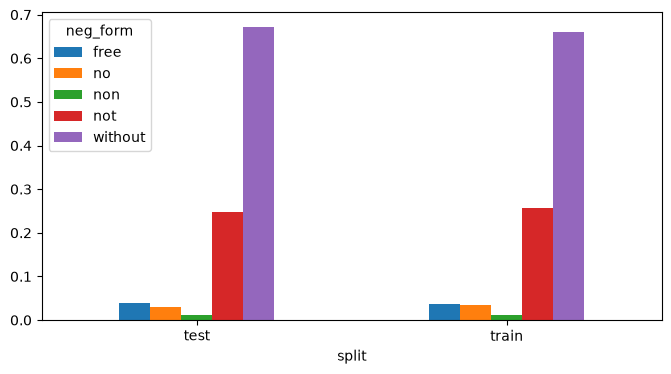

In [88]:
grouped = df_queries.groupby(('split'))['neg_form'].value_counts(normalize=True)
grouped.unstack()

from matplotlib import pyplot as plt

grouped.unstack().plot(kind='bar', stacked=False, figsize=(8, 4), rot=0)
plt.show()

# plt.bar(grouped.unstack(), stacked=False, figsize=(8, 4), rot=0)

否定ありの割合（全クエリの中で）
        全クエリ  否定あり    %
split                  
test    8956   760  8.5
train  20888  1821  8.7


neg_form,free,no,non,not,without
split,,,,,
test,30,22,9,188,511
train,68,61,22,469,1201


/var/folders/k_/xfq6fm9x7419_ttdxwb035v80000gn/T/ipykernel_66254/2158702658.py:18: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/k_/xfq6fm9x7419_ttdxwb035v80000gn/T/ipykernel_66254/2158702658.py:18: UserWarning: Glyph 21542 (\N{CJK UNIFIED IDEOGRAPH-5426}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/k_/xfq6fm9x7419_ttdxwb035v80000gn/T/ipykernel_66254/2158702658.py:18: UserWarning: Glyph 23450 (\N{CJK UNIFIED IDEOGRAPH-5B9A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/k_/xfq6fm9x7419_ttdxwb035v80000gn/T/ipykernel_66254/2158702658.py:18: UserWarning: Glyph 12354 (\N{HIRAGANA LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/k_/xfq6fm9x7419_ttdxwb035v80000gn/T/ipykernel_66254/2158702658.py:18: UserWarning: Glyph 12426 (\N{HIRAGANA LETTER RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/k_/xfq6fm9x7419_ttdxwb03

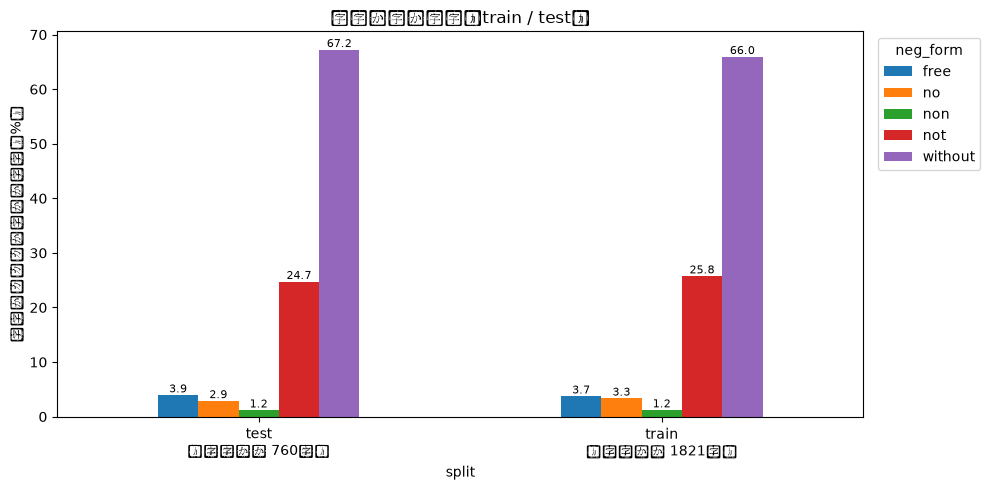

In [89]:
# 件数と割合を一緒に見る（このセルは Claude が書いた・2026-10-30 本人了承）
counts = df_queries.groupby('split')['neg_form'].value_counts().unstack(fill_value=0)   # 件数
ratio = counts.div(counts.sum(axis=1), axis=0) * 100                                   # 否定の中での割合（%）

n_all = df_queries['split'].value_counts()                     # 全クエリ数
n_neg = df_queries['neg_form'].notna().groupby(df_queries['split']).sum()   # 否定ありの数
print('否定ありの割合（全クエリの中で）')
print(pd.DataFrame({'全クエリ': n_all, '否定あり': n_neg, '%': (n_neg / n_all * 100).round(1)}))
display(counts)

ax = ratio.plot(kind='bar', figsize=(10, 5), rot=0)
for bars in ax.containers:                                     # 棒の上に % を出す
    ax.bar_label(bars, fmt='%.1f', fontsize=8)
ax.set_xticklabels([f'{s}\n（否定あり {n_neg[s]}件）' for s in ratio.index])
ax.set_ylabel('否定のクエリの中での割合（%）')
ax.set_title('否定の形の分布（train / test）')
ax.legend(title='neg_form', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 7. まとめて測る（クエリが決まったら）

**なぜ必要？** 1クエリでは「たまたま」か分からない。20件まとめて、モデルごとの平均を見る。

**完成形**
- 1行＝「1クエリ × 1モデル」の表。列：`query_id`・`query`・`model`・`n`（候補数）・`ndcg@10`・`trap@10`
- 20クエリ × 2モデルなら40行
- 最後に `groupby('model')` で平均を出す

**流れ**：`queries` を1つずつ回す → 候補を作る → 2モデルで並べる → 2つの物差しで測る → 辞書にして `rows` に足す → `pd.DataFrame(rows)`

In [90]:
rows = []
# for qid, trap in queries:
#     候補を作る
#     クエリの文を取る（df_q['query'].iloc[0]）
#     2モデルで並べて、測って、rows に足す
for qid, trap in queries:
    df_q = get_candidates(qid, trap)
    query_text = df_q['query'].iloc[0]
    
    #number of candidates
    n_candidates = len(df_q)
    
    #number of trap
    n_trap = df_q['has_trap'].sum()
    
    #number of clean (without trap)
    n_clean = n_candidates - n_trap
    
    #slot
    slots = min(10, n_candidates)   # 候補が10件未満なら、枠は候補の数

    #floor = slots that cannot be filled with clean products / slots
    unfilled = max(0, slots - n_clean)   # 罠でない商品で埋まらない枠（マイナスなら0）
    floor = unfilled / slots
    
    for name, rank in [('TF-IDF', rank_tfidf), ('BM25', rank_bm25)]:
        
        ranked = rank(df_q, query_text)
        ndcg = ndcg_at_k(ranked, k=10)
        trap_rate = trap_rate_at_k(ranked, k=10)
        rows.append({'query_id': qid, 'query':query_text, 'model': name, 'n': len(df_q) , 'ndcg@10': ndcg, 'trap@10': trap_rate, 'trap_floor': floor})
        

results = pd.DataFrame(rows)
results['excess_trap'] = results['trap@10'] - results['trap_floor']
results.groupby('model')[['ndcg@10', 'trap@10', 'trap_floor', 'excess_trap']].mean()

,ndcg@10,trap@10,trap_floor,excess_trap
model,,,,
BM25,0.389487,0.755,0.225,0.53
TF-IDF,0.380419,0.765,0.225,0.54


In [91]:
results

,query_id,query,model,n,ndcg@10,trap@10,trap_floor,excess_trap
0,71987,n95 not kn95 masks,TF-IDF,40,0.473108,0.8,0.4,0.4
1,71987,n95 not kn95 masks,BM25,40,0.277762,0.8,0.4,0.4
2,23909,cat treats without chicken,TF-IDF,41,0.341981,1.0,0.0,1.0
3,23909,cat treats without chicken,BM25,41,0.262944,1.0,0.0,1.0
4,115782,zippered sweatshirt without hood mens,TF-IDF,39,0.475609,0.6,0.0,0.6
5,115782,zippered sweatshirt without hood mens,BM25,39,0.547820,0.7,0.0,0.7
6,1435,100 watt folding solar panel without charge co...,TF-IDF,16,0.362168,0.6,0.0,0.6
7,1435,100 watt folding solar panel without charge co...,BM25,16,0.480280,0.6,0.0,0.6
8,59940,laptop not chromebook,TF-IDF,16,0.016563,1.0,0.6,0.4
9,59940,laptop not chromebook,BM25,16,0.019229,1.0,0.6,0.4


## 7b. 否定なしのクエリと比べる（2026-10-30）

**なぜ必要？** 否定ありの nDCG（0.39）が低いのは「否定のせい」か、「ESCI の検索は普通のクエリでもこのくらい」かを分けるため。
- 否定なしも 0.39 くらい → 否定のせいとは言えない
- 否定なしが高く、否定ありだけ低い → **否定のせい**と言える（v1 の一番大事な結論）

**やり方**（否定ありと同じ枠組みを使い回す）
- test のクエリから、否定の語（6c の `neg_form`）が**ない**ものを seed 42 で1回シャッフル → 上から20件
- `get_candidates` は trap_word が要るので、ありえない語 `'zzzz'` を入れる（罠は0件 → トラップ率は使わず nDCG だけ見る）
- 7番と同じ `rank_tfidf`・`rank_bm25`・`ndcg_at_k` で測る
- このセルのコードは Claude が書いた（7番の使い回し・2026-10-30 本人了承）


#### メモ：否定なしの選び方の読み方（10/30・本人が迷ったところ）
`df_queries[(df_queries['split'] == 'test') & (df_queries['neg_form'].isna())]`
- **左側** `split == 'test'`：test のクエリなら True
- **右側** `neg_form.isna()`：6c の `str.extract` で
  - 否定の語が**あった**クエリ → `neg_form` に**その単語**（例 `'without'`）が入る → 空ではない → `isna()` は **False**
  - 否定の語が**なかった**クエリ → `neg_form` は **NaN（空っぽ）** → `isna()` は **True**
  - ※ 入るのは数字ではなく単語（文字）。NaN は 0 でも False でもなく「何も取れなかった」印
- **`&`**：左も右も True のものだけ残す ＝ **test で、かつ否定の語がないクエリ**
- 同じことは `~df_queries['query'].str.contains(パターン, case=False)` でも書ける（`str.contains` は最初から True／False を返す。`~` は「not」）


In [92]:
# 否定なしのクエリを20件（test・seed 42 で1回シャッフル → 上から20件）
df_plain_test = df_queries[(df_queries['split'] == 'test') & (df_queries['neg_form'].isna())]
df_plain_test = df_plain_test.sample(frac=1, random_state=42).head(20)
plain_queries = list(df_plain_test['query_id'])
df_plain_test[['query_id', 'query']]


,query_id,query
229212,41100,flat black angelus paint
403832,75709,oneplus tv 55 inch
175769,30104,cricut easy pres
493717,94688,small dog brush for yorkie
309875,56898,kamen rider build dx rabbit
96240,13411,basic wiring circuit kit kids
265149,48129,gym set for men dumbells
274755,50118,hellboy toy
180654,31053,cute pajamas for teen girls
379894,71218,mr clean bathroom lemon bathroom vlesner


In [93]:
# 7番と同じループで nDCG だけ測る
rows_plain = []
for qid in plain_queries:
    df_q = get_candidates(qid, 'zzzz')          # 否定なしなので罠の語はダミー
    query_text = df_q['query'].iloc[0]
    for name, rank in [('TF-IDF', rank_tfidf), ('BM25', rank_bm25)]:
        ranked = rank(df_q, query_text)
        rows_plain.append({'query_id': qid, 'query': query_text, 'model': name,
                           'n': len(df_q), 'ndcg@10': ndcg_at_k(ranked, k=10)})
results_plain = pd.DataFrame(rows_plain)

# 否定あり（results）と否定なし（results_plain）を並べる
compare = pd.DataFrame({
    '否定あり nDCG': results.groupby('model')['ndcg@10'].mean(),
    '否定なし nDCG': results_plain.groupby('model')['ndcg@10'].mean(),
})
compare['差（なし − あり）'] = compare['否定なし nDCG'] - compare['否定あり nDCG']
compare


,否定あり nDCG,否定なし nDCG,差（なし − あり）
model,,,
BM25,0.389487,0.680619,0.291131
TF-IDF,0.380419,0.700475,0.320056


### 7b の結果を見ての気づき（自分の言葉で・2026-10-30、誤字だけ直した）
- やっぱり普通に検索すると、まぁそれなりに何もしなくても良くなるってことだよね。無理に1位を取ったりもしなくていいし、トップ10に入れば類似度的にもそうだし、キーワード的にもいっぱい入るってことなんだよね
- やっぱり否定のところで、何を外すのか、外す対象の選択肢が難しいなと思った
- 逆に否定のやつ（否定を言い換えたもの）をやったときには、割と簡単になったりするのかな？
- → ConstraintRAG としては「否定がやっぱり難しい」ことまで分かった（否定なし nDCG 約0.7 vs 否定あり 0.39）

（Claude の補足）「否定を言い換える」は Amazon の否定クエリ書き換えの論文（`papers/negation_rewrite.pdf`）の考え方。v2 の候補


## 8. 気づき（自分の言葉で）
### 7番の結果を見ての仮説（2026-10-29・本人の言葉、誤字だけ直した）
- 結果の見方として、両方とも大体似通っている感じがする
- BM25 は本来なら良いはずなのに、nDCG に関しては TF-IDF の方が良い。エンコーディングの2つの選択肢（BM25 と TF-IDF）で、TF-IDF の方が表面上は良く見えている
- トラップは低ければいい。BM25 の方が高い＝否定の物を入れちゃいけないのに入っている。なら TF-IDF は結構優秀じゃん、となるけど、落とし穴はあるのか？
- 考えられるのは、スコアだけ見れば長さに騙されているのかも。逆に BM25 は頭打ち（キャップ）しているから数字が歪められているとも言えるし、本来の姿を見せてくれているとも言える
- 残る問題：nDCG はラベルを付ける人が画像で見ていた疑いがある。どれも TF-IDF の方が各クエリで高い＝ラベルを付ける側が、本来 Exact match ではない物に Exact match を付けている可能性が高い、という印象。このせいでトラップが上がって、悪いということになっていると思った
- 答え・整理は Obsidian「09c 7クエリの結果の読み方（2026-10-29）」

### 関数をそのままリストに入れて、for で回す（5番、2026-10-29）

**やっていること**
```
for name, rank in [('TF-IDF', rank_tfidf), ('BM25', rank_bm25)]:
    ranked = rank(df_q, query)
```

**Step 1. リストを作る**
- `[('TF-IDF', rank_tfidf), ('BM25', rank_bm25)]` は、（名前, 関数）のペアが2つ入った**1つのリスト**
- `'TF-IDF'` は print 用のただの文字
- `rank_tfidf` は3番で作った**関数そのもの**。`()` を付けていない＝**まだ実行していない**
  - `rank_tfidf()` と書くと、この場で実行しようとする → df_q もクエリも渡していないのでエラー
  - Python では関数も「物」として、リストや変数に入れられる

**Step 2. for で1つずつ取り出す**
- リストの中身が2つなので、**2周**する
- `for name, rank in` ＝ ペアを左右に分けて2つの変数に入れる（アンパック）
  - 1周目：`name = 'TF-IDF'`、`rank = rank_tfidf`
  - 2周目：`name = 'BM25'`、`rank = rank_bm25`
- 分けずに書くと：`for pair in ...:` → `name = pair[0]`、`rank = pair[1]`
- `for i, j in` の j に関数が入っている、と同じ形。`rank` は自分で作った関数ではなく、**その周の関数を入れておく変数**

**Step 3. ループの中で初めて `()` を付けて実行する**
- `ranked = rank(df_q, query)`
  - 1周目は `rank_tfidf(df_q, query)`、2周目は `rank_bm25(df_q, query)` と同じ意味
- `rank` ＝ 関数、`ranked` ＝ その関数が返した **DataFrame**（点の高い順に並んだ表）。名前が似ているので注意

**Step 4. 同じ物差しで測る**
- `ndcg_at_k(ranked, k=10)`・`trap_rate_at_k(ranked, k=10)` → 数字が2つ → print で1行
- 結果は**リストではなく print の行**（モデルごとに出る）

**なぜこう書くのか**
- 同じ処理（並べる → nDCG → トラップ率）を、モデルの数だけコピーしないため
- 名前だけのリスト `['TF-IDF', 'BM25']` だと、中で「TF-IDF なら rank_tfidf」という if 文が要る。関数を一緒に入れれば if が要らない
- モデルを足す（例：埋め込み）ときは、リストに1ペア足すだけ
- 2モデルだけなら、ループなしで2回書いても問題ない。効いてくるのは7番（20クエリ × モデル）

**例え**：`rank_tfidf` ＝ 電子レンジ（道具）、`rank_tfidf(df_q, query)` ＝ 材料を入れて回した結果（料理）。リストに道具を並べ、ループで1つずつ取り出して同じ材料で回している


## 9. 埋め込みを足す（④・2026-10-31）

**なぜ必要？** TF-IDF・BM25 は単語を数える方法。意味で探す埋め込み（all-MiniLM）でも、否定のときだけ nDCG が下がるか・検索のせいが残るかを確かめる。
- 予想は Obsidian 06c の「3. 予想」に書いた（10/31）
- 終わったら 7番・7b のループの `[('TF-IDF', rank_tfidf), ('BM25', rank_bm25)]` に `('埋め込み', rank_embed)` を1つ足す → 3モデルの表になる
- ⚠️ all-MiniLM は長い文の後ろを切る → 商品説明の後半は見ていない（06c）

### 9-1. モデルを1回だけ読む
- `from sentence_transformers import SentenceTransformer`
- `SentenceTransformer('all-MiniLM-L6-v2')` を変数 `model` に入れる
- なぜ関数の外？ 中に書くと、クエリのたびに読み直して遅い。最初の1回だけダウンロード（約90MB）

In [94]:
# 9-1. モデルを1回だけ読む
from sentence_transformers import SentenceTransformer
model = SentenceTransformer('all-MiniLM-L6-v2')

/Users/yyyyy/Mahoroba/constraintrag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1031 21:14:56.629000 66254 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11407.80it/s]


### 9-2. `rank_embed(df_q, query)` を作る
- rank_tfidf と**同じ形**：`score` 列を付けて、点の高い順に並べた表を返す
- ヒント：3・4 は rank_tfidf とまったく同じ
- 確認：7751（radio）で動かして、上位5件のタイトルと score を見る

In [98]:
def rank_embed(df_q, query):
    # 1. doc 列を model.encode でベクトルにする（候補数 × 384）→ doc_vectors
    doc_vectors = model.encode(df_q['doc'].tolist())
    # 2. クエリも model.encode（1 × 384）※ [query] とリストで渡す → query_vector
    query_vector = model.encode([query])
    # 3. cosine_similarity で点数 → .flatten()（↓ rank_tfidf の 3 をそのまま。変数名だけ 1・2 で作ったものに合わせる）
    scores = cosine_similarity(query_vector, doc_vectors).flatten()

    # 4. score 列を足して、高い順に並べて返す（↓ rank_tfidf の 4 をそのまま）
    df_q['score'] = scores
    df_q_sorted = df_q.sort_values(by='score', ascending=False)
    return df_q_sorted  # 並べた表

radiotest = rank_embed(get_candidates(7751, 'radio'), 'alarm clock without radio')
radiotest.head(5)


,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split,product_title,product_description,product_bullet_point,product_brand,product_color,doc,has_trap,score
69333,175953,alarm clock without radio,7751,B09CDHJ4PY,us,E,1,1,test,RunningByte Digital Alarm Clock Radio- AM/FM R...,<b>Decent Alarm Clock with Large Clear Display...,Elegant Digital Alarm Clock radio with Dimmer ...,RunningByte,NaN,RunningByte Digital Alarm Clock Radio- AM/FM R...,1,0.700772
69347,175967,alarm clock without radio,7751,B007T0X5UQ,us,E,1,1,test,RCA Digital Alarm Clock with Night Light,NaN,0.7 inch LED display\nSingle alarm with alarm ...,RCA,Rca Digital Alarm Clock With Night Light,RCA Digital Alarm Clock with Night Light,0,0.671951
69345,175965,alarm clock without radio,7751,B0787W458R,us,I,1,1,test,DreamSky Alarm Clock Radio for Bedroom - FM Ra...,"<b> Decent Alarm Clock with Large, Clear Displ...",Electric Digital Alarm Clock with Full Range D...,DreamSky,Black,DreamSky Alarm Clock Radio for Bedroom - FM Ra...,1,0.666138
69339,175959,alarm clock without radio,7751,B0811KF9TB,us,E,1,1,test,HAPTIME Digital Alarm Clock Radio: 6.2” Large ...,The HAPTIME YGH5230F FM Radio Alarm Clock is m...,Dual Alarms with Multiple Ringtone Options: Ea...,HAPTIME,Black,HAPTIME Digital Alarm Clock Radio: 6.2” Large ...,1,0.635565
69341,175961,alarm clock without radio,7751,B07RKTVQDR,us,E,1,1,test,"Digital Alarm Clock, with Wooden Electronic LE...",▶Extra Features<br> Ⓐ2 time mode: 12 hours & 2...,【Dual plus Alarm Setting】- Updated in 2019 fro...,JALL,Black,"Digital Alarm Clock, with Wooden Electronic LE...",0,0.602298


### 9-3・9-4. 3モデルで測り直す（7番・7b のコピー）
- 7番・7b はそのまま（昨日の2モデルの結果を残す）。ここでは名前に `3` を付けた（results3・results_plain3・compare3）
- 見るところ：①否定ありの埋め込み nDCG は 0.39 より上？ ②否定なしは 0.70 より上？ ③差（なし − あり）は 0.3 より小さい？大きい？ ④検索のせい（0.53）は減った？

In [99]:
# 9-3. 7番と同じ（3モデル・否定あり20件）。昨日の results を上書きしないよう名前を変えた
rows3 = []
# for qid, trap in queries:
#     候補を作る
#     クエリの文を取る（df_q['query'].iloc[0]）
#     3モデルで並べて、測って、rows に足す
for qid, trap in queries:
    df_q = get_candidates(qid, trap)
    query_text = df_q['query'].iloc[0]
    
    #number of candidates
    n_candidates = len(df_q)
    
    #number of trap
    n_trap = df_q['has_trap'].sum()
    
    #number of clean (without trap)
    n_clean = n_candidates - n_trap
    
    #slot
    slots = min(10, n_candidates)   # 候補が10件未満なら、枠は候補の数

    #floor = slots that cannot be filled with clean products / slots
    unfilled = max(0, slots - n_clean)   # 罠でない商品で埋まらない枠（マイナスなら0）
    floor = unfilled / slots
    
    for name, rank in [('TF-IDF', rank_tfidf), ('BM25', rank_bm25), ('埋め込み', rank_embed)]:
        
        ranked = rank(df_q, query_text)
        ndcg = ndcg_at_k(ranked, k=10)
        trap_rate = trap_rate_at_k(ranked, k=10)
        rows3.append({'query_id': qid, 'query':query_text, 'model': name, 'n': len(df_q) , 'ndcg@10': ndcg, 'trap@10': trap_rate, 'trap_floor': floor})
        

results3 = pd.DataFrame(rows3)
results3['excess_trap'] = results3['trap@10'] - results3['trap_floor']
results3.groupby('model')[['ndcg@10', 'trap@10', 'trap_floor', 'excess_trap']].mean()

,ndcg@10,trap@10,trap_floor,excess_trap
model,,,,
BM25,0.389487,0.755,0.225,0.530
TF-IDF,0.380419,0.765,0.225,0.540
埋め込み,0.373333,0.790,0.225,0.565


In [100]:
# 9-4. 7b と同じ（3モデル・否定なし20件）
rows_plain3 = []
for qid in plain_queries:
    df_q = get_candidates(qid, 'zzzz')          # 否定なしなので罠の語はダミー
    query_text = df_q['query'].iloc[0]
    for name, rank in [('TF-IDF', rank_tfidf), ('BM25', rank_bm25), ('埋め込み', rank_embed)]:
        ranked = rank(df_q, query_text)
        rows_plain3.append({'query_id': qid, 'query': query_text, 'model': name,
                           'n': len(df_q), 'ndcg@10': ndcg_at_k(ranked, k=10)})
results_plain3 = pd.DataFrame(rows_plain3)

# 否定あり（results）と否定なし（results_plain）を並べる
compare3 = pd.DataFrame({
    '否定あり nDCG': results3.groupby('model')['ndcg@10'].mean(),
    '否定なし nDCG': results_plain3.groupby('model')['ndcg@10'].mean(),
})
compare3['差（なし − あり）'] = compare3['否定なし nDCG'] - compare3['否定あり nDCG']
compare3


,否定あり nDCG,否定なし nDCG,差（なし − あり）
model,,,
BM25,0.389487,0.680619,0.291131
TF-IDF,0.380419,0.700475,0.320056
埋め込み,0.373333,0.706647,0.333314


In [101]:
# 下限はモデルに関係ないので BM25 の行だけ見る
per_q = (results3[results3['model'] == 'BM25']
         [['query_id', 'query', 'n', 'trap_floor', 'trap@10', 'excess_trap']]
         .sort_values('trap_floor', ascending=False))
per_q

,query_id,query,n,trap_floor,trap@10,excess_trap
46,49760,headphones not wireless,16,0.8,1.0,0.2
52,77730,paper shredder without basket,16,0.6,0.9,0.3
13,59940,laptop not chromebook,16,0.6,1.0,0.4
43,95852,solar lights not motion sensor,40,0.5,1.0,0.5
1,71987,n95 not kn95 masks,40,0.4,0.8,0.4
22,1400,100 headset without micrphone,16,0.4,0.8,0.4
55,75456,olive oil not extra virgin,40,0.4,1.0,0.6
58,447,0.5 pens fine point black not gel,40,0.3,0.8,0.5
19,1509,100w solar panel without controller,16,0.3,0.7,0.4
25,78323,pc headset without microphone,16,0.1,0.4,0.3


### 9-5. クエリごとの下限の読み方（2026-11-01・Claude が整理）
- 0.225 の確認：下限が 0 でないのは11件 → 0.8＋0.6＋0.6＋0.5＋0.4×3＋0.3×2＋0.1×2 ＝ 4.5、÷20 ＝ **0.225** ✅。残り **9件は下限 0**
- 下限 ＝（10 − 普通の数）÷ 10 → 逆算：headphones not wireless は普通が **2件**だけ（0.8）、0.6 → 4件、0.5 → 5件、0.4 → 6件、0.3 → 7件、0.1 → 9件
- 下限はモデルに関係ない（候補＝棚だけで決まる）ので、3モデルとも同じ

**3つのグループ**
- 🟥 全部検索のせい（下限 0 なのに罠だらけ）← v2 で一番効く：cat treats without chicken（0 → 1.0）、glider without ottoman（0 → 1.0）、bed desk without cup holder（0 → 0.9）
- 🟨 棚のせいが大きい：headphones not wireless（1.0 のうち 0.8 が棚、検索のせいは 0.2）
- 🟩 うまくいっている：fidget pack without pop it（0.1）、fountain pen without cartridge（0.3）

**押さえるポイント**：上位10件の約3/4が罠 → うち 0.225 は棚のせい、0.53〜0.57 は検索のせい（＝v2 で下げる所）

**気になる点**：`n`（候補の数）が 16 か 40 前後に分かれている → `get_candidates` に上限があるか、あとで確認


## 10. 有意差（⑤・2026-11-01）
**目的**：0.38 vs 0.70 の差、モデル同士の差が「20件という少なさで、たまたま出たのではないか」を確かめる。モデルは作らない・学習もしない。もう出ている **クエリごとの nDCG** を比べるだけ

**問いは2つ**
| | 問い | 比べるもの | 種類 | 使う関数 |
|---|---|---|---|---|
| A | 否定は普通より本当に低い？ | 否定20件 vs 普通20件（**別々のクエリ**） | 対応なし | `scipy.stats.mannwhitneyu` |
| B | BM25 と埋め込みに本当に差がある？ | **同じ20件**を2つのモデルで | ペア（対応あり） | `scipy.stats.wilcoxon` |

**メモ：ペアと対応なし**
- ペア：同じクエリを2回測る（cat treats を BM25 でも埋め込みでも）→ 1件ずつ「同じ問題での点数差」を見られる
- 対応なし：否定のクエリと普通のクエリは別の問題 → 1対1で引き算する相手がいない → グループ全体を比べる
- どちらも t 検定の仲間。20件と少なく、nDCG は 0 や 1 に偏るので、正規分布を前提にしない版を使う

**読み方**：p < 0.05 → 偶然とは言いにくい差／p ≥ 0.05 → この件数では差があるとは言えない
**予想**：A は p がかなり小さい、B は差が出ない（3モデルほぼ横並び）


In [102]:
# 10-0. 材料（もうある変数。新しく測らない）
# results3       ：否定あり20件 × 3モデル（9-3）。列：query_id, query, model, n, ndcg@10, trap@10, trap_floor
# results_plain3 ：否定なし20件 × 3モデル（9-4）。列：query_id, query, model, n, ndcg@10
from scipy import stats

print(results3['model'].value_counts())
print(results_plain3['model'].value_counts())
results3[['query_id', 'model', 'ndcg@10']].head()


model
TF-IDF    20
BM25      20
埋め込み      20
Name: count, dtype: int64
model
TF-IDF    20
BM25      20
埋め込み      20
Name: count, dtype: int64


,query_id,model,ndcg@10
0,71987,TF-IDF,0.473108
1,71987,BM25,0.277762
2,71987,埋め込み,0.173062
3,23909,TF-IDF,0.341981
4,23909,BM25,0.262944


### 10-A. 否定 vs 普通（対応なし）
ステップ（コードは自分で書く）
1. モデルを1つ決める（例：BM25）
2. `results3` からそのモデルの `ndcg@10` を取り出す → リスト1（20個）
3. `results_plain3` から同じモデルの `ndcg@10` → リスト2（20個）
4. `stats.mannwhitneyu(リスト1, リスト2)` → p 値を見る
5. できたら3モデルを for で回す（7番と同じ形）


In [115]:
# 10-A. 否定 vs 普通（mannwhitneyu）

bm25_neg = results3[results3['model'] == 'BM25'][['ndcg@10']].assign(group='否定あり')

bm25_plain = results_plain3[results_plain3['model'] == 'BM25'][['ndcg@10']].assign(group='普通')

concat_df = pd.concat([bm25_neg, bm25_plain], ignore_index=True)
concat_df['rank'] = concat_df['ndcg@10'].rank()
concat_df.sort_values('rank')

print(concat_df.groupby('group')['rank'].mean())
print()

stat_v, p_value = stats.mannwhitneyu(bm25_neg['ndcg@10'], bm25_plain['ndcg@10'])

print(f"U統計量: {stat_v}, p値: {p_value}")


group
否定あり    13.75
普通      27.25
Name: rank, dtype: float64

U統計量: 65.0, p値: 0.00027451078428318397


### 10-A2. 3モデル全部で（否定 vs 普通）
1. `['TF-IDF', 'BM25', '埋め込み']` を for で回す（7番・9-3 と同じ形）
2. 10-A の `'BM25'` の所を、ループの変数に置き換える
3. `stats.mannwhitneyu` の U と p を辞書にして `rows` に append
4. ループの後で `pd.DataFrame(rows)` → 3行の表


In [118]:
# 10-A2. 3モデルで mannwhitneyu

models = ['TF-IDF', 'BM25', '埋め込み']

for model in models:
    neg = results3[results3['model'] == model][['ndcg@10']].assign(group='否定あり')
    plain = results_plain3[results_plain3['model'] == model][['ndcg@10']].assign(group='普通')
    
    stat_v, p_value = stats.mannwhitneyu(neg['ndcg@10'], plain['ndcg@10'])
    
    print(f"モデル: {model}, U統計量: {stat_v}, p値: {p_value}")

モデル: TF-IDF, U統計量: 45.0, p値: 2.9223449297906545e-05
モデル: BM25, U統計量: 65.0, p値: 0.00027451078428318397
モデル: 埋め込み, U統計量: 51.0, p値: 5.8912066707222565e-05


### 10-B. BM25 vs 埋め込み（ペア）
ステップ（コードは自分で書く）
1. `results3` を「行＝query_id、列＝model、値＝ndcg@10」に並べ替える（ヒント：`pivot`）
2. BM25 の列と埋め込みの列を取り出す（同じ行＝同じクエリでそろっている）
3. `stats.wilcoxon(列1,列2)` → p 値を見る
4. 注意：2つの列がぴったり同じ値ばかりだと警告が出ることがある（差が 0 の行は数えられない）


In [117]:
# 10-B. BM25 vs 埋め込み（wilcoxon）
pivot =results3.pivot(index='query_id', columns='model', values='ndcg@10')
pivot

stat_v, p_value = stats.wilcoxon(pivot['BM25'], pivot['埋め込み'])
print(f"Wilcoxon統計量: {stat_v}, p値: {p_value}")

Wilcoxon統計量: 95.0, p値: 0.7285060882568359


### 10 の結果を見ての気づき（自分の言葉で・2026-11-01、Claude が整理）
**結果**
- 10-A2（否定 vs 普通・各モデル）：TF-IDF U=45, p=2.9e-05／BM25 U=65, p=0.00027／埋め込み U=51, p=5.9e-05
- 10-B（BM25 vs 埋め込み・否定20件）：W=95, p=0.73

**勘違いしていたところ**
- `e-05` は「× 10 のマイナス5乗」。2.9e-05 ＝ 0.000029。3 や 6 に見えたのは 0.0000**3**・0.0000**6** の部分 → 3モデルとも 0.05 よりずっと小さい
- p が小さい ＝ 「たまたまではない」という**証拠が強い**。差が大きい・モデルが良い、ではない（差の大きさは U／400 や nDCG の平均の差で見る）
- 埋め込みの p が小さい ＝ 埋め込みが良い、ではなく逆。**意味を見るはずの埋め込みでも、否定で nDCG が落ちることがはっきりしている**
- 10-A2 は「同じモデルの中で否定 vs 普通」。モデル同士の比較は 10-B

**まとめ**
- 否定で落ちるのは、どのモデルでも本物（10-A2）
- モデルを替えても落ち方は変わらない（10-B）
- ✅ 言い方：「3モデルとも、否定クエリで nDCG が有意に低い（p < 0.001）。埋め込みでも改善しない」
- ❌「埋め込みが一番良い」／「否定だから悪かった」（原因はまだ言えない → 同じクエリで否定あり・なしを比べるのは v2）


## 11. 失敗例の分類（2026-11-01）
**目的**：「うまくいったのはたまたまか、理由があるか」に答える／v2 で何を直せば効くかの根拠にする
**やり方**：**手作業でラベルを付ける**（20件・1件 3分くらい → 約1時間）。機械にやらせるのは「タイトルを並べて見せる」ところまで

**なぜ上位のタイトルを見る？**
- trap（罠）は「除外語が**商品タイトル**に入っているか」（in_title）で判定している → タイトルを見れば、なぜ罠になったかが分かる
- 上位10件＝検索が「いちばん合う」と判断したもの → そこに何が来ているかが、検索の失敗の中身

**ラベル（1件に1つ、迷ったら主なもの）**
| ラベル | 意味 | 例 |
|---|---|---|
| A 除外語に反応 | 除外語（chicken など）がクエリにある語として一致し、それを含む商品が上に来る | cat treats without chicken → チキン入りが上位 |
| B 棚のせい | 下限が高く、普通の商品が足りない。並べ方では直らない | headphones not wireless（下限 0.8） |
| C ラベルの見落とし | ESCI の人のラベルが否定を見落としている（人のミス）。例：radio なしと頼んだのに、ラジオ付き時計が E | 前に見た 15件中3件 |
| D 判定のズレ | タイトルに除外語がないのに実は含む／タイトルにあるのに実は含まない（in_title の限界） | ラジオっぽく見えない時計 など |
| E うまくいった | 普通の商品が十分あり、上位のタイトルに除外語がほぼ出てこない | fidget pack・fountain pen |

**否定の形**：not と without で落ち方が違うか、最後に件数で比べる（表の「否定の形」列はクエリから機械的に入れた）


### 11-1. 1件ずつ見るためのセル（コードは自分で書く）
ステップ
1. 否定クエリを1つ選ぶ（query_id）
2. そのクエリの候補を作る（`get_candidates`）→ BM25 で並べる（`rank_bm25`）
3. 上位10件の「タイトル・ESCI ラベル（E/S/C/I）・罠かどうか」を表で出す
4. 見ながら下の表にラベルとひとことを書く


In [139]:
# 11-1. 1件ずつ見る（このセルは Claude が書いた・2026-11-01 本人了承：分析に集中するため）
pd.set_option('display.max_colwidth', 90)
trap_of = dict(queries)          # {query_id: 除外語}

def show_top(qid, model=rank_bm25, k=10):
    trap = trap_of[qid]
    df_q = get_candidates(qid, trap)
    query_text = df_q['query'].iloc[0]
    ranked = model(df_q, query_text)
    n_clean = (df_q['has_trap'] == 0).sum()
    print(f"[{qid}] {query_text}  ／ 除外語: '{trap}'  ／ 候補 {len(df_q)} 件（罠でない {n_clean} 件）")
    top = ranked.head(k)[['product_title', 'esci_label', 'has_trap', 'score']].reset_index(drop=True)
    top.index = top.index + 1    # 1位から
    return top

# 使い方：qid を変えて実行（まずは 23909 = cat treats without chicken）
show_top(447)


[447] 0.5 pens fine point black not gel  ／ 除外語: 'gel'  ／ 候補 40 件（罠でない 7 件）


,product_title,esci_label,has_trap,score
1,"TUL Retractable Gel Pens 0.5mm Needle Point Fine, Black/Blue Bundle (2 4-packs)",I,1,6.591043
2,"Sharpie S-Gel, Gel Pens, Ultra Fine Point (0.38mm), Black, 4 Count",I,1,5.842520
3,"Sharpie S-Gel, Gel Pens, Ultra Fine Point (0.38mm), Black, 12 Count",I,1,5.776330
4,"Sharpie S-Gel, Gel Pens, Fine Point (0.5mm), Black Ink Gel Pen, 12 Count",I,1,5.764952
5,"12 Pieces Rolling Ball Pens, Quick-Drying Ink 0.5 mm Extra Fine Point Pens Liquid Ink ...",E,0,5.717606
6,"Paper Mate 1951638 InkJoy Gel Pens, Fine Point, Black, 3 Count",E,1,5.593259
7,"Paper Mate InkJoy Gel Pens, Fine Point, Black, 10 Count",S,1,5.593259
8,"Deli 8 Colored Liquid Ink Pens, Ultra Fine Point (0.5 mm), 8 Assorted Colors Marker Pe...",S,0,5.558633
9,"Paper Mate InkJoy Gel Pens, Fine Point, Black, 12 Count - 1951720",E,1,5.523605
10,"JoyNote Black Gel Pens, 6 Pack Fine Point Writing Pen for Office, 0.5mm Tips with Prem...",I,1,5.274356


In [120]:
# 20件の query_id と除外語（ここから選んで show_top に入れる）
for qid, trap in queries:
    print(qid, trap)


71987 kn95
23909 chicken
115782 hood
1435 controller
59940 chromebook
40132 pop it
1509 controller
1400 microphone
78323 microphone
99719 hood
28603 straw
7752 snooze
42300 cartridge
14476 cup holder
95852 motion
49760 wireless
45968 ottoman
77730 basket
75456 extra virgin
447 gel


### 11-2. ラベル表（2026-11-01・本人の分析を Claude が表にした。詳しくは Obsidian `16 失敗例の分類`）
| # | クエリ | 否定の形 | 下限 | trap@10 | excess | ラベル | ひとこと（なぜ） |
|---|---|---|---|---|---|---|---|
| 1 | headphones not wireless | not | 0.8 | 1.0 | 0.2 | B（＋A） | 罠でない2件だけ＝棚のせい。"wired" と言い換えればいい（クエリ書き換えが効きそう） |
| 2 | paper shredder without basket | without | 0.6 | 0.9 | 0.3 | D（＋B） | 上位4つは E で「without waste basket」＝ほしい商品なのに has_trap＝1。basket と waste basket は同じ意味 |
| 3 | laptop not chromebook | not | 0.6 | 1.0 | 0.4 | B＋A | 罠でない4件。1位が Chromebook の交換用キーボード（短い文書が有利・"not" も単語として一致） |
| 4 | solar lights not motion sensor | not | 0.5 | 1.0 | 0.5 | B＋A | 罠でない5件。motion sensor に反応。not のかかる範囲（スコープ）の問題も |
| 5 | n95 not kn95 masks | not | 0.4 | 0.8 | 0.4 | A＋B＋C | n95 と kn95 は別の単語だが、kn95 に一致して点。KN95 なのに E も |
| 6 | 100 headset without micrphone | without | 0.4 | 0.8 | 0.4 | B | クエリの打ち間違い（micrphone）→ タイトルと一致せず点が低い。ほぼ I |
| 7 | olive oil not extra virgin | not | 0.4 | 1.0 | 0.6 | A＋B | 4語全部一致で score が高い（6.2）が、ほぼ extra virgin 入り |
| 8 | 0.5 pens fine point black not gel | not | 0.3 | 0.8 | 0.5 | A＋C | 上位4つがゲルペン。ゲルペンなのに E もある |
| 9 | 100w solar panel without controller | without | 0.3 | 0.7 | 0.4 | A＋B＋C | controller 付きを「仕方なく S」（S を甘く付ける傾向）。C も1件 |
| 10 | pc headset without microphone | without | 0.1 | 0.4 | 0.3 | E | E・S が大多数。1400 との違いは打ち間違いがないこと |
| 11 | alarm clock without snooze | without | 0.1 | 0.7 | 0.6 | A＋B＋C | 1位が「スヌーズ付き」なのに E |
| 12 | sweatshirt without hood for men | without | 0.0 | 0.7 | 0.7 | A＋C | 1〜3位は同じ商品に見えるのに E・S・I に割れた |
| 13 | cat treats without chicken | without | 0.0 | 1.0 | 1.0 | A＋C | 上位10件すべて chicken 入り。8位だけ I、ほかは E・S |
| 14 | fountain pen without cartridge | without | 0.0 | 0.3 | 0.3 | E | 罠3件だけ。I が E より上に来る所はある |
| 15 | bed desk without cup holder | without | 0.0 | 0.9 | 0.9 | A＋C | 1位は関係ない商品。E は2件で、その E にも罠 |
| 16 | fidget pack without pop it | without | 0.0 | 0.1 | 0.1 | E | 否定は守れた。でもラベルはバラバラ（否定を守る＝必要だが十分ではない） |
| 17 | glider without ottoman | without | 0.0 | 1.0 | 1.0 | A | 罠でない21件あるのに全部オットマン入り |
| 18 | 100 watt folding solar panel without charge co… | without | 0.0 | 0.6 | 0.6 | D（＋A）※qid 要確認 | 2位に「without controller」＝ほしい商品なのに罠に数えられる |
| 19 | zippered sweatshirt without hood mens | without | 0.0 | 0.7 | 0.7 | A＋C | hood 入りなのに E が多い。1位は I のスポーツウェア |
| 20 | contigo without straw | without | 0.0 | 0.7 | 0.7 | A | 罠でない33件あるのに、罠7件が全部上位 |

### 11-3. 集計（メインのラベルで数える）
- **A 除外語に反応：10件**（cat treats・glider・bed desk・contigo・sweatshirt×2・n95・pens・olive oil・100w solar）
- **B 棚のせい：5件**（headphones・laptop・solar lights・100 headset・alarm clock）
- **D 判定のズレ：2件**（paper shredder・100 watt folding solar）
- **E うまくいった：3件**（pc headset・fountain pen・fidget pack）
- **C ラベルの見落とし（サブで）：7件**（n95・pens・100w solar・alarm clock・sweatshirt×2・cat treats）
- **not と without の違い**：not の6件は下限の平均 **0.50**、without の14件は **0.11**。not のクエリは「主流の型を外す」（wireless・chromebook・kn95・extra virgin・gel）ので、棚が罠だらけになりやすい。E はすべて without
- **見えてきた型**：除外語が補完品（controller）／部品が本体に勝つ（交換用キーボード）／クエリの打ち間違い（micrphone）／同じ意味の別の言い方（waste basket）／否定のスコープ（not motion sensor）
- 気づき（自分の言葉で・2026-11-01、これまでの発言から抜粋・誤字だけ直した）
  - 罠が入っていても、basket と waste basket のように**同じ意味で呼び方が違うだけ**のものがある。has_trap があるから一概に下げるのは危険。否定の対象がどこからどこまでか（スコープ）に加えて、縦の軸として同じ類義語にあたるかも見る必要がある
  - **without** は商品の一部にかかる。「フードなし」のように、物自体はほしいけど、この部分は今回のニーズに合わないから外して、というわかりやすい外し方
  - **not** は「〇〇 not 〇〇」のように、ほしいものが先に決まっていて、そのあと念を押すための「これではないからね」。強調の意思が強い。それを検索窓に入れると、検索の意図が取りづらい
  - 同じ否定でも、部分に対してなのか、種類に対してなのか、いくつかの種類に分ける必要がある
  - 同じ単語が入っているのに E だったり I だったり、ラベル付けがおかしいものが何回も出てきて、人のミスの印象が強かった（ただ数で見るとメインは A）
  - solar lights not motion sensor：not がかかる範囲（スコープ）が間違っているのでは
  - score が高いと良く見えて、score に惑わされている自分がいる（score はクエリ同士では比べられない）
  - S でもユーザー目線ではいい気がしてきた。でも nDCG では S はほぼ点にならない
